# Week 7: Text and Multimodal AI (Lab 7)
**Project 2: Deep Learning Applications | Individual**

**Before you run:** (1) Settings → Internet **On** (EasyOCR downloads its models). (2) Add Data → *SMS Spam Collection Dataset* (uciml). (3) Add your private dataset **week6-model** (contains `week6_model.pt`) and your Week 6 image dataset (for the example image). (4) Run All.

Every part ends with a **Write it** cell. The domain used here is the Week 6 model's: **solar-panel condition** (classes: Bird-drop, Clean, Dusty, Electrical-damage, New, Physical-Damage, Snow-Covered).

## Results at a glance
| Part | Measured result |
|---|---|
| 1 TF-IDF | hand calculation = library (win 0.584, free 0.445, cash 0.584, now 0.345); cosine(d2, d3) = 0.544 |
| 2 Text classification | macro-F1 **0.974** (word, 12,128 features) vs **0.982** (char, 36,449 features); spam P/R 0.979/0.933 vs 0.986/0.953 |
| 3 NER (provided set) | F1 **0.533 → 0.875** with 7 rules (16 gold entities) |
| 3 NER (solar domain, held-out) | F1 **0.370 → 0.759** with 4 domain rules |
| 4 Regex | 5/5 provided tests and 6/6 solar tests pass |
| 5 OCR | unit-test CER 0.062 / 0.059 / 0.143 → 0.000; EasyOCR on clean synthetic images: CER 0.000 |
| 6 Case record | P(Electrical-damage) = 0.803 → REFER; PII masked; disagreement case flagged for review |

## Notation used in the equations
$N$ = number of documents, $\mathrm{df}(t)$ = documents containing term $t$, $TP/FP/FN$ = true positives / false positives / false negatives, $P$ = precision, $R$ = recall, $\sigma(z)=1/(1+e^{-z})$, $\lVert\cdot\rVert_2$ = Euclidean length, $\mathrm{lev}$ = Levenshtein edit distance.

Each code cell below is preceded by a **heading and a description** (what it does, the equation, and the calculation worked from the saved output).

## Setup (shared imports and helpers)

#### Cell 1 · Setup: imports, shared helpers and the results store
**What it does.** Loads every library used later (NumPy, pandas, matplotlib, Pillow, PyTorch, torchvision), creates the dictionary `RESULTS` (every measured number is stored there) and defines `find_file()`, which searches `/kaggle/input/**` for a file by name. The search is needed because Kaggle mounts datasets under different folders, e.g. `spam.csv` was found at `/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv` and `week6_model.pt` at `/kaggle/input/models/.../week6-model/.../week6_model.pt`.

**Output:** none (setup only).

In [16]:
import os, re, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
warnings.filterwarnings('ignore')

RESULTS = {}          # every measured number is stored here and reused in the README cell

def find_file(filename, extra_dirs=('.',)):
    """Kaggle mounts datasets under different layouts, so search instead of hard-coding."""
    hits = sorted(glob.glob(f'/kaggle/input/**/{filename}', recursive=True))
    for d in extra_dirs:
        p = os.path.join(d, filename)
        if os.path.exists(p):
            hits.append(p)
    if not hits:
        raise FileNotFoundError(
            f'{filename} not found. Add the dataset in the Input panel (Add Data) and re-run.')
    return hits[0]

## Part 1: TF-IDF by Hand (10 min)

#### Cell 2 · TF-IDF with scikit-learn, reproduced by hand
**What it does.** Builds a TF-IDF matrix for three tiny messages (`win free cash now`, `call me now`, `free call now`) with `TfidfVectorizer`, then recomputes document d1 manually and checks that both agree.

**Equations (scikit-learn's smooth IDF + L2 normalisation).** With $N$ documents and document frequency $\mathrm{df}(t)$:

$$\mathrm{idf}(t)=\ln\frac{1+N}{1+\mathrm{df}(t)}+1,\qquad \mathrm{tfidf}(t,d)=\mathrm{tf}(t,d)\cdot\mathrm{idf}(t),\qquad \hat v_d=\frac{v_d}{\lVert v_d\rVert_2}$$

**Calculation for d1** ($N=3$, every term occurs once so tf = 1):

| term | df | idf | idf² | normalised value |
|---|---|---|---|---|
| win | 1 | ln(4/2)+1 = 1.6931 | 2.8667 | 1.6931 / 2.8968 = **0.584** |
| free | 2 | ln(4/3)+1 = 1.2877 | 1.6581 | 1.2877 / 2.8968 = **0.445** |
| cash | 1 | ln(4/2)+1 = 1.6931 | 2.8667 | **0.584** |
| now | 3 | ln(4/4)+1 = 1.0000 | 1.0000 | 1.0000 / 2.8968 = **0.345** |

Length: $\lVert v\rVert=\sqrt{2.8667+1.6581+2.8667+1}=\sqrt{8.3916}=2.8968$. **Result:** the hand calculation `{'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}` is identical to row d1 of the library table, so the library is verified.

In [17]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score)
nlp = spacy.load('en_core_web_sm')     # preinstalled on Kaggle
nlp_base = nlp                         # untouched baseline, never given a ruler
print('spaCy', spacy.__version__)
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                 # smooth idf + L2 normalization
X = vec.fit_transform(docs)
tfidf_table = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                           index=['d1', 'd2', 'd3'])
print(tfidf_table.round(3))
# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
print({w: round(float(x), 3) for w, x in zip(idf, v / np.linalg.norm(v))})

spaCy 3.8.16
     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}


#### Cell 3 · IDF arithmetic for "free" and "now" and the cosine similarity of d2 and d3
**What it does.** Prints the IDF working for two words and computes the cosine similarity of d2 (`call me now`) and d3 (`free call now`) from the TF-IDF table.

**Equation.** Because all vectors already have length 1, cosine similarity is just the dot product:

$$\cos(a,b)=\frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}=a\cdot b$$

**Calculation from the output.**

$$\mathrm{idf}(\text{free})=\ln\tfrac43+1=0.2877+1=1.2877\qquad \mathrm{idf}(\text{now})=\ln\tfrac44+1=0+1=1.0000$$

$$\cos(d_2,d_3)=\underbrace{0.548\times0.620}_{\text{call}}+\underbrace{0.425\times0.481}_{\text{now}}=0.340+0.204=\mathbf{0.544}\approx0.54\ \text{(slide 10)}$$

In [18]:
# Write-it helper: IDF arithmetic and the d2/d3 cosine similarity
print(f"idf(free) = ln(4/3) + 1 = {np.log(4/3):.4f} + 1 = {np.log(4/3)+1:.4f}")
print(f"idf(now)  = ln(4/4) + 1 = {np.log(4/4):.4f} + 1 = {np.log(4/4)+1:.4f}")
cos_d2_d3 = float(tfidf_table.loc['d2'] @ tfidf_table.loc['d3'])   # vectors already have length 1
print(f"cosine(d2, d3) = 0.548*0.620 + 0.425*0.481 = {cos_d2_d3:.3f}   (slide 10: 0.54)")
RESULTS['cos_d2_d3'] = round(cos_d2_d3, 3)

idf(free) = ln(4/3) + 1 = 0.2877 + 1 = 1.2877
idf(now)  = ln(4/4) + 1 = 0.0000 + 1 = 1.0000
cosine(d2, d3) = 0.548*0.620 + 0.425*0.481 = 0.544   (slide 10: 0.54)


**Write it: Part 1**

- **IDF of "free"** (appears in 2 of 3 docs): ln((1+3)/(1+2)) + 1 = ln(4/3) + 1 = 0.2877 + 1 = **1.288**.
- **IDF of "now"** (appears in all 3 docs): ln((1+3)/(1+3)) + 1 = ln(1) + 1 = 0 + 1 = **1.000**.
- "now" gets the lowest weight because it occurs in every message, so it cannot tell one message from another. Its logarithmic part is zero and only the "+1" smoothing is left. "win" and "cash" (1 doc each, IDF = ln(4/2)+1 = 1.693) are rarer, so they weigh more. After L2 scaling d1 becomes win 0.584, free 0.445, cash 0.584, now 0.345, identical in both printouts.
- **Cosine of d2 and d3** (vectors are already length 1, so it is just the dot product). Shared terms are "call" and "now": 0.548 × 0.620 + 0.425 × 0.481 = 0.340 + 0.204 = **0.544 ≈ 0.54**, matching slide 10. "call" is rarer than "now", so it drives the similarity.

## Part 2: Text Classification (20 min)

### Task 2.1: Load and inspect

#### Cell 4 · Task 2.1: load and inspect the SMS Spam Collection
**What it does.** Reads `spam.csv` (Latin-1 encoded), keeps the label and text columns, and creates the numeric target $y$ (1 = spam, 0 = ham). It prints class counts and the "always ham" baseline.

**Equations.**

$$\text{spam share}=\frac{n_{\text{spam}}}{n}\qquad \text{always-ham accuracy}=1-\text{spam share}$$

**Calculation from the output:** $n=4825+747=5572$ messages. Spam share $=747/5572=\mathbf{0.134}$; always-ham accuracy $=4825/5572=\mathbf{0.866}$. A useful model must therefore beat 86.6 % accuracy, which is why macro-F1 (not accuracy) is used.

In [19]:
path = find_file('spam.csv')      # works for both Kaggle input layouts
print('Reading', path)
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")
RESULTS['n_texts'] = len(sms)

Reading /kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv
label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


### Task 2.2: Word n-gram classifier

#### Cell 5 · Task 2.2: word 1-2 gram TF-IDF + Logistic Regression
**What it does.** Splits the data 80/20 (stratified, `random_state=42`: 4,457 train, 1,115 test), builds a pipeline `TfidfVectorizer(1-2 grams, min_df=2, sublinear_tf=True)` → `LogisticRegression(class_weight='balanced')`, trains it, and prints the classification report and confusion matrix.

**Equations.**

$$\mathrm{tf}_{\text{sublinear}}=1+\ln(\mathrm{tf}),\qquad P(\text{spam}\mid x)=\sigma(w\cdot x+b)=\frac{1}{1+e^{-(w\cdot x+b)}}$$

Class weights ("balanced") make the rare class count more: $\;w_c=\dfrac{n}{2\,n_c}$. Training set: $n=4457$, ham $=3859$, spam $=598$, so $w_{\text{ham}}=4457/(2\cdot3859)=0.577$ and $w_{\text{spam}}=4457/(2\cdot598)=3.727$. Sublinear tf example: a word seen 3 times counts $1+\ln3=2.10$, not 3.

**Metric definitions** (spam is the positive class): $\;P=\dfrac{TP}{TP+FP},\;\; R=\dfrac{TP}{TP+FN},\;\; F_1=\dfrac{2PR}{P+R},\;\; \text{macro-}F_1=\dfrac{F_1^{\text{ham}}+F_1^{\text{spam}}}{2}$

**Calculation from the output** (149 spam and 966 ham in the test set; 3 ham flagged, 10 spam missed):

$$TP=149-10=139,\quad P_{\text{spam}}=\tfrac{139}{139+3}=0.979,\quad R_{\text{spam}}=\tfrac{139}{149}=0.933,\quad F_1^{\text{spam}}=\tfrac{2(0.979)(0.933)}{0.979+0.933}=0.955$$

$$F_1^{\text{ham}}=0.993\ \Rightarrow\ \text{macro-}F_1=\tfrac{0.993+0.955}{2}=\mathbf{0.974},\qquad \text{accuracy}=\tfrac{139+963}{1115}=0.988$$

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



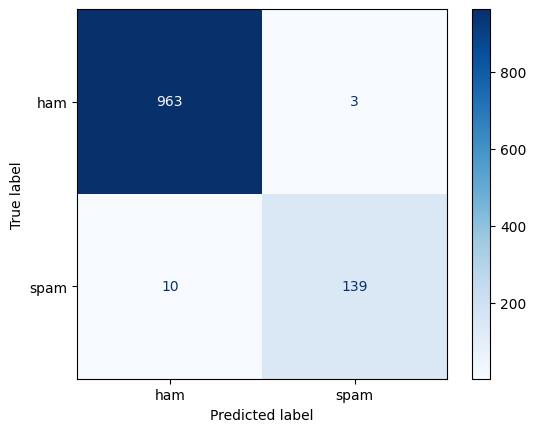

In [20]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])
word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

### Task 2.3: What did it learn?

#### Cell 6 · Task 2.3: what did the word model learn?
**What it does.** Reads the Logistic Regression coefficient $w_j$ of every n-gram and lists the 12 most positive (spam-like) and 12 most negative (ham-like).

**Equation.** The coefficient is a change in log-odds, so a feature multiplies the odds of spam by $e^{w_j}$ when it is present:

$$\ln\frac{P(\text{spam})}{1-P(\text{spam})}=w\cdot x+b\ \Longrightarrow\ \text{odds ratio per unit of feature }j=e^{w_j}$$

**Reading the output.** Spam-like: `call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your` (calls to action and premium-rate vocabulary, sensible). Ham-like: `my, me, ok, that, it, but, ll, gt, lt, can, what, da` (personal chat words). Suspicious shortcuts: `to` and `your` are common function words, and `gt` / `lt` come from HTML escapes (`&gt;`, `&lt;`) in the data, not from meaning.

In [21]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


### Task 2.4: Character n-grams

#### Cell 7 · Task 2.4: character n-gram model and robustness to spelling tricks
**What it does.** Trains the same classifier on `char_wb` 2-5 grams (pieces of characters inside word boundaries), prints macro-F1 and the number of features for both models, and scores two tricky messages.

**Equation (how many character n-grams a word gives).** A word is padded with spaces, so "free" becomes `" free "` (length $L=6$) and yields $L-n+1$ n-grams for each $n$:

$$\sum_{n=2}^{5}(L-n+1)=5+4+3+2=14\ \text{n-grams per word},$$

so misspellings such as `FR33` still share pieces like `" f"`, `fr`, `"e "` with `free`.

**Calculation from the output.**

| model | macro-F1 | features |
|---|---|---|
| word 1-2 grams | 0.974 | 12,128 |
| char 2-5 grams | **0.982** | 36,449 |

Gain = 0.982 − 0.974 = **+0.008** for $36449/12128\approx3.0\times$ more features. Tricky messages: `W1N a FR33 pr1ze!! txt CLAIM now` → P(spam) = 0.85 (log-odds $\ln\frac{0.85}{0.15}=+1.73$, caught); `kal milte hain, 5 baje` → 0.12 (log-odds $\ln\frac{0.12}{0.88}=-1.99$, correctly ham).

In [22]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)
for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')
# Robustness to spelling tricks
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print(dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


#### Cell 8 · Both models side by side, plus my own tricky messages
**What it does.** Builds one comparison table (macro-F1, spam precision, spam recall, false positives and false negatives) and scores three messages of my own with both models: Roman Urdu spam, disguised "leetspeak" spam, and Roman Urdu ham. It also stores the main numbers in `RESULTS`.

**Equations.** Same as Cell 5: $P=\frac{TP}{TP+FP}$, $R=\frac{TP}{TP+FN}$, $F_1=\frac{2PR}{P+R}$. A message is called spam when $P(\text{spam})\ge0.5$.

**Calculation for the char model** (FP = 2, FN = 7, so $TP=149-7=142$, $TN=966-2=964$):

$$P_{\text{spam}}=\tfrac{142}{144}=0.986,\quad R_{\text{spam}}=\tfrac{142}{149}=0.953,\quad F_1^{\text{spam}}=0.969,\quad F_1^{\text{ham}}=0.995,\quad \text{macro-}F_1=\tfrac{0.995+0.969}{2}=\mathbf{0.982}$$

**Reading the output.** The char model is better on every column: errors fall from 13 (3 FP + 10 FN) to 9 (2 FP + 7 FN).

| my message | word P(spam) | char P(spam) | verdict |
|---|---|---|---|
| Roman Urdu spam ("Mubarak ho! ... inam jeeta hai ...") | 0.63 | 0.49 | word catches it; char misses by 0.01 |
| leetspeak spam ("Y0u h4ve w0n a fr33 g1ft c@rd!! ...") | 0.17 | 0.42 | both miss; char is closer |
| Roman Urdu ham ("Kal office aa jana, meeting 5 baje hai") | 0.13 | 0.09 | both correct |

In [23]:
# Both models side by side: macro-F1 plus spam precision and recall (needed for the Write-it)
rows = []
for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    rows.append({'model': name,
                 'macro-F1': f1_score(y_te, p, average='macro'),
                 'spam precision': precision_score(y_te, p),
                 'spam recall': recall_score(y_te, p),
                 'false positives (ham->spam)': int(((p == 1) & (y_te == 0)).sum()),
                 'false negatives (spam->ham)': int(((p == 0) & (y_te == 1)).sum())})
cmp_df = pd.DataFrame(rows).set_index('model').round(3)
print(cmp_df.to_string())
RESULTS['word_f1'] = float(cmp_df.loc['word 1-2 grams', 'macro-F1'])
RESULTS['char_f1'] = float(cmp_df.loc['char 2-5 grams', 'macro-F1'])
RESULTS['top_pos'] = list(terms[order[-5:]][::-1])
RESULTS['top_neg'] = list(terms[order[:5]])

# Two tricky messages of my own (Roman Urdu spam and disguised spam), scored by BOTH models
mine = ['Mubarak ho! Aap ne 50000 ka inam jeeta hai. Abhi call karein aur claim karein',
        'Y0u h4ve w0n a fr33 g1ft c@rd!! Cl1ck n0w t0 cl@im',
        'Kal office aa jana, meeting 5 baje hai']
tbl = pd.DataFrame({'word P(spam)': word_clf.predict_proba(mine)[:, 1].round(2),
                    'char P(spam)': char_clf.predict_proba(mine)[:, 1].round(2)}, index=mine)
pd.set_option('display.max_colwidth', 90)
print(tbl.to_string())

                macro-F1  spam precision  spam recall  false positives (ham->spam)  false negatives (spam->ham)
model                                                                                                          
word 1-2 grams     0.974           0.979        0.933                            3                           10
char 2-5 grams     0.982           0.986        0.953                            2                            7
                                                                               word P(spam)  char P(spam)
Mubarak ho! Aap ne 50000 ka inam jeeta hai. Abhi call karein aur claim karein          0.63          0.49
Y0u h4ve w0n a fr33 g1ft c@rd!! Cl1ck n0w t0 cl@im                                     0.17          0.42
Kal office aa jana, meeting 5 baje hai                                                 0.13          0.09


### Task 2.5: Error analysis

#### Cell 9 · Task 2.5: error analysis of the word model
**What it does.** Collects every test message the word model got wrong and sorts them by predicted spam probability, so the most confident mistakes are at the extremes.

**Equation (the error rule).** A message is an error when the thresholded prediction disagrees with the label:

$$\text{error}\iff\mathbb{1}[P(\text{spam})\ge0.5]\ne y$$

**Calculation from the output.** 13 errors in 1,115 messages: 10 spam with $P<0.5$ (from 0.088 up to 0.465) and 3 ham with $P\ge0.5$ (0.621, 0.636, 0.853). Error rate $=13/1115=1.17\%$, which equals $1-\text{accuracy}=1-0.988$. The Write-it cell below classifies each as model error, label error or ambiguous.

In [24]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

**Write it: Part 2**

**Scores (test set, 1,115 messages).** Word 1-2 grams: macro-F1 **0.974**, spam precision 0.979, spam recall 0.933. Char 2-5 grams: macro-F1 **0.982**; its spam precision is **0.986** and recall **0.953** (2 false positives, 7 missed spam, versus 3 and 10 for the word model). Always-ham would score 0.866 accuracy, so accuracy alone is not useful. The char model has about three times as many features (36,449 vs 12,128) for a gain of about 0.8 points of macro-F1.

**Top features.** Spam: *call, txt, free, text, reply, claim, stop, mobile, www, uk*. Mostly sensible (calls to action, premium-rate vocabulary). Possible shortcuts: **"to"** and **"your"** are function words that simply occur more in long, promotional messages, and **"call"** is so strong that the genuine ham message "Waiting for your call." (p = 0.85) is misclassified because of it. Ham: *my, me, ok, can, what, da*: personal chat words. **"gt" and "lt"** are leftovers of HTML escapes (`&gt;`, `&lt;`) in the dataset, a data artifact rather than meaning.

**Error analysis (word model, 13 errors: 10 missed spam, 3 false alarms).**

| Message (start) | Verdict |
|---|---|
| "Do you realize that in about 40 years... tattoos?" (labelled spam) | label error |
| "Hi ya babe x u 4goten bout me?' scammers getting smart..." | genuinely ambiguous (a warning *about* spam) |
| "ringtoneking 84484" | model error (very short, spam-like) |
| "For sale - arsenal dartboard..." | genuinely ambiguous (looks like a personal ad) |
| "ROMCAPspam Everyone around should be responding well..." | model error (horoscope subscription spam) |
| "Sorry I missed your call... I'm on 07090201529" | genuinely ambiguous (callback scam style) |
| "Latest News! Police station toilet stolen..." | genuinely ambiguous (joke-subscription spam) |
| "FreeMsg Hey there darling... std chgs to send, 1.50 to rcv" | model error |
| "Download as many ringtones as u like... Txt Sir to 80082" | model error |
| "Can U get 2 phone NOW? ... Call me NOW on 09096102316..." | model error |
| "We have sent JD for Customer Service cum Accounts Executive..." (ham) | genuinely ambiguous (recruiter-style text labelled ham) |
| "Ok... Ur typical reply..." (ham) | model error |
| "Waiting for your call." (ham) | model error (the "call" shortcut) |

**Tricky messages.** The char model gave 0.85 to "W1N a FR33 pr1ze!! txt CLAIM now" (caught despite the digit-for-letter tricks, because pieces like "txt", "claim", "now" and "!!" still match) and 0.12 to the Roman Urdu ham "kal milte hain, 5 baje" (correctly ham). My own three messages (word / char P(spam)): Roman Urdu spam "Mubarak ho! ... inam jeeta hai ..." **0.63 / 0.49**; leetspeak spam "Y0u h4ve w0n a fr33 g1ft c@rd!!..." **0.17 / 0.42**; Roman Urdu ham "Kal office aa jana, meeting 5 baje hai" **0.13 / 0.09**. So the char model helps with disguised spelling (0.42 vs 0.17, though still under the 0.5 threshold), but neither model reliably catches Roman Urdu spam: the word model barely does (0.63) and the char model barely misses (0.49). Reason: the SMS data is English and has almost no Roman Urdu, so the fix is to add labelled Roman Urdu and obfuscated examples to training, not just to change the features.

## Part 3: Named Entity Recognition, Measured (20 min)

### Task 3.1: Out of the box

#### Cell 10 · Task 3.1: spaCy NER out of the box on Pakistani sentences
**What it does.** Defines six local sentences and prints the entities `en_core_web_sm` finds, as (text, label) pairs.

**Reading the output (vs what a careful human marks).**

| spaCy said | Should be |
|---|---|
| `Engro Fertilizers` → PERSON | ORG |
| `30/09/2026` → GPE | DATE |
| `0300-1234567` → DATE | a phone number (regex, not NER) |
| `250,000` → CARDINAL | MONEY, including "Rs." |
| `Farmer Muhammad Aslam` → PERSON | PERSON: `Muhammad Aslam` (title included by mistake) |
| `PIMS Islamabad` → LOC | ORG `PIMS` + GPE `Islamabad` |

The model was trained mostly on US/European news, so local names, formats and currency are out of distribution.

In [25]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp_base(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Task 3.2: Score against a gold set

#### Cell 11 · Task 3.2: gold annotations and the entity-level scorer
**What it does.** Stores what a careful human would mark as sets of (text, label) per sentence and defines `ner_scores()`. An entity counts as correct only if its exact text **and** its label match.

**Equations** (sets: predicted $\hat E$, gold $G$):

$$TP=|\hat E\cap G|,\quad FP=|\hat E\setminus G|,\quad FN=|G\setminus\hat E|,\quad P=\tfrac{TP}{TP+FP},\quad R=\tfrac{TP}{TP+FN},\quad F_1=\tfrac{2PR}{P+R}=\tfrac{2TP}{2TP+FP+FN}$$

**Calculation from the output.** The gold set has $4+3+2+1+3+3=16$ entities. Reported $P=0.571$ and $R=0.500$ correspond to $TP=8$, $FP=6$, $FN=8$:

$$P=\tfrac{8}{14}=0.571,\quad R=\tfrac{8}{16}=0.500,\quad F_1=\tfrac{2\cdot8}{2\cdot8+6+8}=\tfrac{16}{30}=\mathbf{0.533}$$

In [26]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]
def ner_scores(nlp_model, sents=None, golds=None):
    sents = sentences if sents is None else sents
    golds = gold if golds is None else golds
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)                  # exact text AND label
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f1, 3)}

print('spaCy out of the box:', ner_scores(nlp_base))
RESULTS['ner_base'] = ner_scores(nlp_base)['f1']

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


### Task 3.3: Add rules before the statistical model

#### Cell 12 · Task 3.3: add rules (entity ruler) before the statistical model
**What it does.** Defines seven local patterns (a MONEY token pattern for `pkr`/`rs`/`rs.` + number, ORG names, the FAC `Karachi Port`, and a dd/mm/yyyy DATE regex) and builds a pipeline with an `entity_ruler` placed **before** `ner`, so rules win over the statistical guess. `build_nlp()` creates a fresh pipeline each time, so re-running the cell cannot raise "entity_ruler already exists".

**Calculation from the output.** $P=R=0.875$ with 16 gold entities means $TP=14$, $FP=2$, $FN=2$:

$$F_1=\tfrac{2\cdot14}{2\cdot14+2+2}=\tfrac{28}{32}=\mathbf{0.875}$$

**Improvement:** $0.875-0.533=+0.342$ F1 (precision $+0.304$, recall $+0.375$) from seven rules.

In [27]:
LOCAL_PATTERNS = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
]

def build_nlp(*pattern_lists):
    """Fresh pipeline + entity_ruler BEFORE the statistical NER.
    Building from scratch each time makes the cell safe to re-run
    (adding 'entity_ruler' twice to the same pipeline raises ValueError)."""
    model = spacy.load('en_core_web_sm')
    ruler = model.add_pipe('entity_ruler', before='ner')
    for plist in pattern_lists:
        ruler.add_patterns(plist)
    return model

nlp = build_nlp(LOCAL_PATTERNS)
print('spaCy + entity ruler:', ner_scores(nlp))
RESULTS['ner_rules'] = ner_scores(nlp)['f1']

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


### Now do it for your domain (solar panels): first 5 sentences write the rules, last 5 are held out

#### Cell 13 · NER for my domain (solar panels): rules from 5 sentences, tested on 5 held-out sentences
**What it does.** Defines 10 solar-domain sentences with gold annotations. Sentences 1-5 are the development set that the four domain rules (Jinko Solar, K-Electric, Huawei, Quaid-e-Azam Solar Park) were written from; sentences 6-10 are held out so the score is not optimistic. It scores spaCy before and after rules on both sets and prints the errors that remain.

**Equation.** Same entity-level scoring as Cell 11: $F_1=\dfrac{2TP}{2TP+FP+FN}$.

**Calculation from the output.**

| | dev (first 5) | held-out (last 5) |
|---|---|---|
| spaCy out of the box | 0.485 | 0.370 |
| spaCy + entity ruler | 0.848 | **0.759** |

Held-out set: 15 gold entities. After rules the printout lists 4 missed and 3 spurious entities, so $TP=15-4=11$, $FP=3$, $FN=4$:

$$P=\tfrac{11}{14}=0.786,\quad R=\tfrac{11}{15}=0.733,\quad F_1=\tfrac{22}{22+3+4}=0.759$$

Held-out gain: $0.759-0.370=+0.389$. The dev score is higher than the held-out one ($0.848>0.759$) because the rules were written from the dev sentences, as expected.

In [28]:
# My domain: solar-panel inspection and procurement in Pakistan (edit freely to use your own sentences)
dom_sentences = [
    # --- development set (rules are written from these five) ---
    'Engineer Usman Tariq inspected the Quaid-e-Azam Solar Park near Bahawalpur on 14/03/2026.',
    'Jinko Solar shipped 120 panels worth PKR 3,600,000 to Lahore on 05/04/2026.',
    'Technician Hamza Malik from Faisalabad reported a hot spot on the rooftop array.',
    'K-Electric charged Rs. 18,500 for net metering at the Karachi office on Monday.',
    'Call Huawei support at 0321-7654321 or email service@huawei.com.pk.',
    # --- held-out set (never looked at while writing rules) ---
    'Technician Sana Iqbal cleaned the dusty panels at Multan Solar Farm on 02/05/2026.',
    'Jinko Solar replaced the cracked panels for PKR 450,000 on 20/06/2026.',
    'Engineer Bilal Raza from Islamabad inspected the inverter on Friday.',
    'K-Electric approved the net metering request of Ali Hassan for Rs. 22,000.',
    'Huawei will visit Peshawar on 15/07/2026 to repair the faulty inverter.']

dom_gold = [
    {('Usman Tariq', 'PERSON'), ('Quaid-e-Azam Solar Park', 'FAC'),
     ('Bahawalpur', 'GPE'), ('14/03/2026', 'DATE')},
    {('Jinko Solar', 'ORG'), ('120', 'CARDINAL'), ('PKR 3,600,000', 'MONEY'),
     ('Lahore', 'GPE'), ('05/04/2026', 'DATE')},
    {('Hamza Malik', 'PERSON'), ('Faisalabad', 'GPE')},
    {('K-Electric', 'ORG'), ('Rs. 18,500', 'MONEY'), ('Karachi', 'GPE'),
     ('Monday', 'DATE')},
    {('Huawei', 'ORG')},
    # held-out
    {('Sana Iqbal', 'PERSON'), ('Multan Solar Farm', 'FAC'), ('02/05/2026', 'DATE')},
    {('Jinko Solar', 'ORG'), ('PKR 450,000', 'MONEY'), ('20/06/2026', 'DATE')},
    {('Bilal Raza', 'PERSON'), ('Islamabad', 'GPE'), ('Friday', 'DATE')},
    {('K-Electric', 'ORG'), ('Ali Hassan', 'PERSON'), ('Rs. 22,000', 'MONEY')},
    {('Huawei', 'ORG'), ('Peshawar', 'GPE'), ('15/07/2026', 'DATE')}]
assert len(dom_sentences) == len(dom_gold) == 10

# Rules written ONLY from sentences 1-5 (names + formats seen there)
DOMAIN_PATTERNS = [
    {'label': 'ORG', 'pattern': 'Jinko Solar'},
    {'label': 'ORG', 'pattern': 'K-Electric'},
    {'label': 'ORG', 'pattern': 'Huawei'},
    {'label': 'FAC', 'pattern': 'Quaid-e-Azam Solar Park'},
]
# The MONEY and dd/mm/yyyy DATE rules already live in LOCAL_PATTERNS, so reuse them
nlp_dom = build_nlp(LOCAL_PATTERNS, DOMAIN_PATTERNS)

dev_s, dev_g = dom_sentences[:5], dom_gold[:5]
held_s, held_g = dom_sentences[5:], dom_gold[5:]
table = pd.DataFrame({
    'dev (first 5)':     [ner_scores(nlp_base, dev_s, dev_g)['f1'],  ner_scores(nlp_dom, dev_s, dev_g)['f1']],
    'held-out (last 5)': [ner_scores(nlp_base, held_s, held_g)['f1'], ner_scores(nlp_dom, held_s, held_g)['f1']],
}, index=['spaCy out of the box', 'spaCy + entity ruler'])
print(table.to_string())
RESULTS['dom_base_heldout'] = table.loc['spaCy out of the box', 'held-out (last 5)']
RESULTS['dom_rules_heldout'] = table.loc['spaCy + entity ruler', 'held-out (last 5)']

# Which held-out errors remain after the rules?
for s, g in zip(held_s, held_g):
    pred = {(e.text, e.label_) for e in nlp_dom(s).ents}
    if pred != g:
        print('\n', s, '\n   missed :', sorted(g - pred), '\n   spurious:', sorted(pred - g))

                      dev (first 5)  held-out (last 5)
spaCy out of the box          0.485              0.370
spaCy + entity ruler          0.848              0.759

 Technician Sana Iqbal cleaned the dusty panels at Multan Solar Farm on 02/05/2026. 
   missed : [('Multan Solar Farm', 'FAC'), ('Sana Iqbal', 'PERSON')] 
   spurious: [('Multan Solar Farm', 'ORG'), ('Technician Sana Iqbal', 'PERSON')]

 Engineer Bilal Raza from Islamabad inspected the inverter on Friday. 
   missed : [('Bilal Raza', 'PERSON')] 
   spurious: []

 Huawei will visit Peshawar on 15/07/2026 to repair the faulty inverter. 
   missed : [('Peshawar', 'GPE')] 
   spurious: [('Peshawar', 'ORG')]


**Write it: Part 3**

**Provided sentences (16 gold entities).** spaCy out of the box: precision 0.571, recall 0.500, **F1 0.533**. After 7 rules: precision 0.875, recall 0.875, **F1 0.875**. The rules fix the local ORG names (Engro Fertilizers was labelled PERSON), the "Rs./PKR" amounts (250,000 was a bare CARDINAL) and the dd/mm/yyyy date (labelled GPE). The model was trained mostly on US/European news, so Pakistani names, currency and date formats are out of distribution.

**My solar domain (10 sentences).** F1 before and after rules, on the first 5 (where the rules came from) and on the held-out 5, is in the table above: dev **0.485 → 0.848**, held-out **0.370 → 0.759** (out of the box → with rules). The held-out number is the honest one, because the rules never saw those sentences.

**Errors that remain after the rules** are printed below the table (held-out: TP = 11, FP = 3, FN = 4, so P = 0.786 and R = 0.733). They are: *Multan Solar Farm* labelled ORG instead of FAC, *Technician Sana Iqbal* as one PERSON span (the title is included, so the exact text does not match), *Bilal Raza* not found at all, and *Peshawar* labelled ORG instead of GPE. My choice of fix: **names and facilities → a gazetteer/entity-ruler list** (cheap, exact, but it only covers names I have listed); **formats like phones, CNICs, dates → regex** (Part 4), not NER, because they follow a fixed pattern; **open-ended names of people and places → a model trained on my own annotated data** once I have a few hundred sentences, because rules never cover every new name. Ten sentences is far too few to train a model, so rules and regex are the right tools today.

## Part 4: Regex Fields with Negative Tests (10 min)

#### Cell 14 · Part 4: regex fields (CNIC, mobile, amount, date, email, invoice) with positive and negative tests
**What it does.** Defines six regular expressions, `extract_fields()` (runs all patterns with `re.IGNORECASE` and returns only the fields found), and five tests. Positive tests must find fields; negative tests must find nothing.

**How the key patterns work.**

| field | pattern | idea |
|---|---|---|
| CNIC | `\b\d{5}-\d{7}-\d\b` | exactly 5-7-1 digits; `\b` stops it matching inside a longer number |
| mobile | `(?:\+92[- ]?\|\b0)3\d{2}[- ]?\d{7}\b` | `+92` or leading `0`, then `3` + 2 digits, then exactly 7 digits |
| amount | `(?:PKR\|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)` | currency word, then digits/commas, optional 1-2 decimals (the `( )` captures the number) |
| date | `\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b` | d/m/yyyy or d-m-yyyy |

**Calculation from the output:** all 5 tests print `PASS`: 3 positives found their fields (e.g. `35202-1234567-1`, `12,500.50`, `4417`), and both negatives returned `{}`: `12345678901234` has 14 digits (a CNIC needs 5-7-1 with dashes) and `0300` has only 4 digits, not 11.

In [29]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
}
def extract_fields(text, patterns=None):
    patterns = PATTERNS if patterns is None else patterns
    out = {}
    for name, pat in patterns.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    got = extract_fields(text)
    status = 'PASS' if bool(got) == expect else 'FAIL'
    print(f'{status} {str(expect):5s} {got}   <- {text}')

PASS True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
PASS True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
PASS False {}   <- Order 12345678901234 shipped
PASS False {}   <- Room 0300 on floor 3


#### Cell 15 · Domain regex patterns for solar panels, a "too greedy" pattern and its fix, and negative tests
**What it does.** Adds four solar patterns (`panel_id`, `serial`, `power_wp`, `voltage`), merges them with the provided ones into `ALL_PATTERNS`, shows a loose pattern matching too much, and runs six domain tests (2 positive, 4 negative).

**Pattern logic.**

| field | pattern | meaning |
|---|---|---|
| panel_id | `\bSP-\d{4}\b` | `SP-` followed by exactly 4 digits |
| serial | `\b[A-Z]{3}\d{7}\b` | 3 letters + 7 digits |
| power_wp | `\b\d{3,4}\s?Wp?\b` | 3-4 digits, optional space, `W` or `Wp`, then a word boundary |
| voltage | `\b\d{2,3}(?:\.\d{1,2})?\s?V\b` | 2-3 digits, optional decimals, `V` |

**Too-greedy pattern.** The loose `SP-\d+` returned `['SP-1042', 'SP-99', 'SP-12345678']`: it matched inside `ASP-99` (no left boundary) and swallowed an 8-digit number (no exact count). The fixed `\bSP-\d{4}\b` returned only `['SP-1042']`.

**Calculation from the output:** 6/6 domain tests passed. The negatives are rejected for exact reasons: `SP-12` (2 digits, needs 4), `500 Watts` and `48 Volts` (no word boundary after `W` / `V`), `2024 West` (same), and `12345678` (no 3-letter prefix).

In [30]:
# Domain patterns (solar panels) + negative tests of my own
DOMAIN_FIELD_PATTERNS = {
    'panel_id': r'\bSP-\d{4}\b',                         # SP-1042
    'serial':   r'\b[A-Z]{3}\d{7}\b',                    # ABC1234567
    'power_wp': r'\b\d{3,4}\s?Wp?\b',                    # 550 Wp, 550W
    'voltage':  r'\b\d{2,3}(?:\.\d{1,2})?\s?V\b',        # 49.5 V
}
ALL_PATTERNS = {**PATTERNS, **DOMAIN_FIELD_PATTERNS}

# A pattern that matched too much, and the fix
loose = r'SP-\d+'                      # no word boundary, any number of digits
text = 'Panel SP-1042 failed; ticket ASP-99 and SP-12345678 are unrelated.'
print('loose pattern :', re.findall(loose, text))
print('fixed pattern :', re.findall(DOMAIN_FIELD_PATTERNS['panel_id'], text))

domain_tests = [
    # (text, expected set of field names that must be found; empty set = must find nothing in the domain patterns)
    ('Panel SP-1042 rated 550 Wp at 49.5 V, serial ABC1234567', {'panel_id', 'power_wp', 'voltage', 'serial'}),
    ('Inverter output fell to 220 V on SP-2201', {'voltage', 'panel_id'}),
    ('Room SP-12 on floor 3', set()),                  # ID needs exactly 4 digits
    ('He ordered 500 Watts of 48 Volts power', set()), # unit must end at a word boundary
    ('Call 2024 West Road, VIP gate 12', set()),       # "2024 W" / "12 V" must not be a rating
    ('Order 12345678 shipped', set()),                 # no 3-letter prefix, so not a serial
]
passed = 0
for text, expect in domain_tests:
    got = set(extract_fields(text, DOMAIN_FIELD_PATTERNS))
    ok = got == expect
    passed += ok
    print(('PASS' if ok else 'FAIL'), sorted(got), '<-', text)
print(f'{passed}/{len(domain_tests)} domain tests passed')
RESULTS['regex_fields'] = ['cnic', 'mobile', 'amount', 'date', 'email', 'invoice'] + list(DOMAIN_FIELD_PATTERNS)
n_neg = 2 + sum(not e for _, e in domain_tests)     # 2 provided + my own negatives
RESULTS['regex_neg'] = f'{n_neg} negative tests, all clean' if passed == len(domain_tests) else 'see failing tests'

loose pattern : ['SP-1042', 'SP-99', 'SP-12345678']
fixed pattern : ['SP-1042']
PASS ['panel_id', 'power_wp', 'serial', 'voltage'] <- Panel SP-1042 rated 550 Wp at 49.5 V, serial ABC1234567
PASS ['panel_id', 'voltage'] <- Inverter output fell to 220 V on SP-2201
PASS [] <- Room SP-12 on floor 3
PASS [] <- He ordered 500 Watts of 48 Volts power
PASS [] <- Call 2024 West Road, VIP gate 12
PASS [] <- Order 12345678 shipped
6/6 domain tests passed


**Write it: Part 4**

**Provided patterns:** CNIC `\b\d{5}-\d{7}-\d\b`, mobile `(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b`, amount, date, email, invoice number. All three positive tests found their fields; both negative tests ("Order 12345678901234 shipped" and "Room 0300 on floor 3") returned nothing.

**My solar patterns:** `panel_id` `\bSP-\d{4}\b`, `serial` `\b[A-Z]{3}\d{7}\b`, `power_wp` `\b\d{3,4}\s?Wp?\b`, `voltage` `\b\d{2,3}(?:\.\d{1,2})?\s?V\b`. Test results are printed above: two positive tests and four negative tests (an ID with only two digits, "500 Watts / 48 Volts" spelled-out units, "2024 West Road / VIP gate 12", and an 8-digit number with no letter prefix). All should read PASS.

**A pattern that matched too much:** my first panel-ID pattern was `SP-\d+`. It matched inside "ASP-99" (no left boundary) and swallowed "SP-12345678" (any number of digits). Fixing it took three tools: a **word boundary** `\b` on both sides, an **exact count** `\d{4}` instead of `\d+`, and a fixed prefix. The same lesson applies to the power pattern: without the closing `\b`, "500 Watts" would have matched as "500 W".

## Part 5: Character Error Rate and OCR Repair (10 min)

### Task 5.1: CER and context rules

#### Cell 16 · Task 5.1: Levenshtein distance, character error rate and context-based OCR repair
**What it does.** Implements edit distance, CER, and `fix_ocr()` (letters that look like digits, such as `O`→`0` and `l`/`I`→`1`, are repaired only **inside numbers**; `N0.` becomes `No.`). It tests three reference/OCR pairs.

**Equations.** Edit distance is computed row by row with the recurrence

$$d_{i,j}=\min\big(d_{i-1,j}+1,\;d_{i,j-1}+1,\;d_{i-1,j-1}+\mathbb{1}[a_i\ne b_j]\big),\qquad \mathrm{CER}=\frac{S+D+I}{N}=\frac{\mathrm{lev}(\text{ref},\text{hyp})}{N}$$

**Calculation from the output** ($N$ = reference length in characters):

| reference | OCR | edits | CER before | CER after fix |
|---|---|---|---|---|
| `Invoice No. 4417` | `Invoice N0. 4417` | 1 | 1/16 = **0.062** | 0.000 |
| `Total: PKR 12,500` | `Total: PKR 12,5O0` | 1 | 1/17 = **0.059** | 0.000 |
| `Due 30/09/2026` | `Due 3O/09/2O26` | 2 | 2/14 = **0.143** | 0.000 |

A CER of 0.06 sounds small, but one wrong digit makes a whole amount or ID wrong.

In [31]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]
def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)
def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)                # N-zero -> No.
    return text
pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


### Task 5.2: OCR on an invoice

#### Cell 17 · Task 5.2: OCR on a synthetic invoice (EasyOCR)
**What it does.** Draws a five-line invoice image, reads it with EasyOCR, collapses whitespace so line breaks do not count as errors, and reports CER before and after `fix_ocr()`, plus **field-level accuracy**.

**Equations.**

$$\mathrm{CER}=\frac{\mathrm{lev}(\text{truth},\text{OCR})}{|\text{truth}|},\qquad \text{field accuracy}=\frac{\#\{\text{fields whose extracted value equals the truth}\}}{\#\{\text{fields in the truth}\}}$$

**Calculation from the output.** The OCR text equals the truth exactly: $\mathrm{lev}=0$, so $\mathrm{CER}=0/|\text{truth}|=\mathbf{0.000}$ both before and after the fixes. Field-level accuracy $=4/4=\mathbf{1.00}$ (amount, date, mobile, invoice number). The repair rules had nothing to fix here.

In [32]:
# EasyOCR needs Internet On the first time (it downloads ~100 MB of models)
OCR_OK = False
try:
    import easyocr
    reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
    OCR_OK = True
except Exception as e:
    print('EasyOCR is not available:', type(e).__name__, str(e)[:200])
    print('Fix: Settings -> Internet On (and `!pip install easyocr` if the import failed), then re-run this cell.')

def get_font(size=30):
    """DejaVuSans lives in different places on different machines; try them all, then fall back."""
    candidates = ['/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
                  os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
                  '/usr/share/fonts/dejavu/DejaVuSans.ttf']
    for p in candidates:
        if os.path.exists(p):
            return ImageFont.truetype(p, size)
    try:
        return ImageFont.load_default(size)        # Pillow >= 10.1
    except TypeError:
        return ImageFont.load_default()

norm = lambda s: ' '.join(s.split())               # ignore line-break layout

def ocr_cer(lines, fname, size=(900, 330)):
    """Render `lines` to an image, OCR it, and return (raw_text, cleaned_text, CER raw, CER fixed)."""
    img = Image.new('RGB', size, 'white')
    d = ImageDraw.Draw(img)
    font = get_font(30)
    for k, line in enumerate(lines):
        d.text((30, 20 + 60 * k), line, fill='black', font=font)
    img.save(fname)
    ocr_text = '\n'.join(t for _, t, c in reader.readtext(fname))
    truth = norm(' '.join(lines))
    raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
    return truth, raw, clean, cer(truth, raw), cer(truth, clean)

def field_accuracy(truth, hyp, patterns):
    """Share of fields found in the truth whose extracted values are identical in the OCR text."""
    t, h = extract_fields(truth, patterns), extract_fields(hyp, patterns)
    return sum(h.get(k) == v for k, v in t.items()) / max(len(t), 1), len(t)

# A synthetic invoice so everyone has the same test document.
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
if OCR_OK:
    truth, raw, clean, cer_raw, cer_fix = ocr_cer(lines, 'invoice.png')
    print(raw)
    print(f'CER raw {cer_raw:.3f}   after fixes {cer_fix:.3f}')
    fa, nf = field_accuracy(truth, raw, PATTERNS)
    fb, _ = field_accuracy(truth, clean, PATTERNS)
    print(f'Field-level accuracy ({nf} fields): raw {fa:.2f}   after fixes {fb:.2f}')
    RESULTS['cer_raw'], RESULTS['cer_clean'] = round(cer_raw, 3), round(cer_fix, 3)
else:
    print('Skipped: OCR engine not available (see message above).')

Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000
Field-level accuracy (4 fields): raw 1.00   after fixes 1.00


#### Cell 18 · A second OCR test from my own domain (solar inspection label)
**What it does.** Repeats Cell 17 on a four-line solar label (panel ID, rated power and voltage, inspection date and name, serial number) using hand-typed reference lines, and scores field-level accuracy with `ALL_PATTERNS`.

**Calculation from the output.** $\mathrm{CER}=0/|\text{truth}|=\mathbf{0.000}$ before and after; field-level accuracy $=5/5=\mathbf{1.00}$ (panel_id, power_wp, voltage, date, serial). As with the invoice, a clean synthetic image is the easiest possible case (see the Write-it for Part 5).

In [33]:
# A second document from MY domain: a solar-panel inspection label, hand-typed truth = `lines2`
lines2 = ['Panel SP-1042  Jinko Solar', 'Rated power 550 Wp   Voltage 49.5 V',
          'Inspected 12/09/2026 by Hamza Malik', 'Serial ABC1234567']
if OCR_OK:
    truth2, raw2, clean2, c_raw2, c_fix2 = ocr_cer(lines2, 'label.png', size=(900, 270))
    print(raw2)
    print(f'CER raw {c_raw2:.3f}   after fixes {c_fix2:.3f}')
    fa, nf = field_accuracy(truth2, raw2, ALL_PATTERNS)
    fb, _ = field_accuracy(truth2, clean2, ALL_PATTERNS)
    print(f'Field-level accuracy ({nf} fields): raw {fa:.2f}   after fixes {fb:.2f}')
    RESULTS['cer_label_raw'], RESULTS['cer_label_clean'] = round(c_raw2, 3), round(c_fix2, 3)

Panel SP-1042 Jinko Solar Rated power 550 Wp Voltage 49.5 V Inspected 12/09/2026 by Hamza Malik Serial ABC1234567
CER raw 0.000   after fixes 0.000
Field-level accuracy (5 fields): raw 1.00   after fixes 1.00


**Write it: Part 5**

**Unit tests (slides 26 and 27):** CER before the fixes was 0.062, 0.059 and 0.143, and 0.000 for all three after `fix_ocr`. Each is edits ÷ reference length: 1/16, 1/17 and 2/14.

**Invoice and label OCR:** CER before and after correction is printed above for both the shared invoice and my solar inspection label: invoice CER **0.000 → 0.000**, field accuracy 4/4; solar label CER **0.000 → 0.000**, field accuracy 5/5. My raw CER was already 0.000, so the repair rules had nothing to fix. That is because the image is synthetic: perfectly clean black text on a white background, a single regular font, no blur, no perspective, no shadows, no JPEG noise. A phone photo of a real invoice or a panel nameplate adds glare, skew, low resolution and stamps, so I expect a much higher raw CER (several percent or more) and a smaller gain from the simple "O → 0, l → 1" rules, which only fix one family of errors. A CER of a few percent still ruins fields: one wrong digit in an amount or ID makes the whole field wrong, which is why field-level accuracy is printed next to CER.

## Part 6: Image + Text Case Record (20 min)

### Task 6.1: Mask personal identifiers

#### Cell 19 · Task 6.1: mask personal identifiers (CNIC, phone, email)
**What it does.** `mask_pii()` replaces CNIC, mobile and email matches by `[CNIC]`, `[PHONE]` and `[EMAIL]` using the same regex patterns as Part 4. It is run **before** any entity or field extraction.

**Calculation from the output.** `CNIC 35202-1234567-1, call 0300-1234567, a@b.pk` → `CNIC [CNIC], call [PHONE], [EMAIL]`: 3 identifiers masked. Negative test: `Room 0300 on floor 3, panel SP-1042, order 12345678901234` is unchanged, so ordinary numbers survive masking (0 false masks).

In [34]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))
# negative test: ordinary numbers must survive masking
print(mask_pii('Room 0300 on floor 3, panel SP-1042, order 12345678901234'))

CNIC [CNIC], call [PHONE], [EMAIL]
Room 0300 on floor 3, panel SP-1042, order 12345678901234


### Task 6.2: Load your Week 6 model and build evidence functions

#### Cell 20 · Task 6.2: load the Week 6 model and build the evidence functions
**What it does.** Loads the checkpoint `week6_model.pt`, rebuilds the architecture from its saved settings (no download), and defines `image_evidence()` (class probabilities), `text_evidence()` (entities, regex fields, urgent terms) and the list `URGENT` of solar warning words (`hot spot, burn, spark, smoke, melt, short circuit, spreading, crack, no output, shock`).

**Equation (image evidence).** The network outputs 7 raw scores (logits) $z_k$, converted to probabilities by softmax:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{7}e^{z_j}},\qquad \sum_k p_k=1$$

**Reading the output.** Checkpoint: `resnet18`, `img_size 224`, `grayscale False`, 7 classes: Bird-drop, Clean, Dusty, Electrical-damage, New, Physical-Damage, Snow-Covered. The classifier head is a `Linear(512, 7)` layer.

In [35]:
# Combine your Week 6 image model with text evidence into one record.
W6_PATH = find_file('week6_model.pt')      # searches /kaggle/input/** and the working directory
print('Checkpoint:', W6_PATH)
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('backbone', ckpt['backbone'], '| classes', classes,
      '| img_size', ckpt['img_size'], '| grayscale', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# Warning terms from MY domain (solar panels): damage and fire-risk wording
URGENT = ['hot spot', 'burn', 'spark', 'smoke', 'melt', 'short circuit',
          'spreading', 'crack', 'no output', 'shock']

nlp_full = build_nlp(LOCAL_PATTERNS, DOMAIN_PATTERNS)     # Pakistani + solar rules

def text_evidence(note):
    doc = nlp_full(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note, ALL_PATTERNS),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

Checkpoint: /kaggle/input/models/fahadkayani786/week6-model/pytorch/default/1/week6_model.pt
backbone resnet18 | classes ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'New', 'Physical-Damage', 'Snow-Covered'] | img_size 224 | grayscale False


### Task 6.3: One transparent record

#### Cell 21 · Task 6.3: one transparent, masked case record (image + text)
**What it does.** `case_record()` masks the note first, gets image probabilities from the Week 6 model and text evidence from the masked note, and applies transparent rules. The example uses an `Electrical-damage` image and a note about burn marks and a hot spot. A final assertion checks that no phone or CNIC digits survive.

**Decision rule (late fusion by rules).** With threshold $\tau=0.5$ and image probability $p=P(\text{Electrical-damage})$:

$$\text{image flag}=\mathbb{1}[p\ge\tau],\qquad \text{text flag}=\mathbb{1}[\text{urgent terms}\ne\varnothing],\qquad \text{REFER if any flag is set},\ \text{review if flags differ}$$

(For a weighted average instead of rules, late fusion is $p_{\text{fused}}=w\,p_{\text{img}}+(1-w)\,p_{\text{txt}}$; see Question 5.)

**Calculation from the output.**
- Probabilities sum to $0.040+0.009+0.021+0.803+0.049+0.071+0.007=1.000$ ✓.
- $p=0.803\ge0.5$ → image flag set; urgent terms `hot spot, burn, spreading` → text flag set; both agree → `REFER` with two reasons.
- Masking worked: `note_masked` shows `[CNIC]` and `[PHONE]`, and the privacy check passed.
- Wrong entities in `text_evidence`: `Technician Hamza Malik` (PERSON includes the title), `Gulberg Lahore` as one FAC, `550` as CARDINAL, and `CNIC` as ORG (twice, from the `[CNIC]` placeholder). None changes the decision.

In [36]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    image_flag, text_flag = p >= threshold, bool(txt_ev['urgent_terms'])
    if image_flag != text_flag:
        reasons.append('image and note DISAGREE: human review required')
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'modalities_agree': image_flag == text_flag,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

def find_example_image(class_name):
    """First image inside any folder named like the class, anywhere under /kaggle/input."""
    exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    for root, _, files in os.walk('/kaggle/input'):
        if os.path.basename(root).lower() == class_name.lower():
            for f in sorted(files):
                if f.lower().endswith(exts):
                    return os.path.join(root, f)
    return None

POSITIVE = 'Electrical-damage'            # the class I must not miss (fire / safety risk)
EXAMPLE_IMAGE = find_example_image(POSITIVE)     # or set a path by hand
CLEAN_IMAGE = find_example_image('Clean')
if EXAMPLE_IMAGE is None:
    raise FileNotFoundError('No image found. Add your Week 6 dataset in the Input panel, '
                            'or set EXAMPLE_IMAGE = "/kaggle/input/.../your_image.jpg".')

note = ('Technician Hamza Malik inspected the rooftop array at Gulberg Lahore on 12/09/2026. '
        'Burn marks and a hot spot near panel SP-1042 (550 Wp) are spreading. '
        'Owner CNIC 35202-1234567-1, mobile 0300-1234567.')
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
out = json.dumps(rec, indent=2, ensure_ascii=False)
print(out)

# Privacy check: no digit of the phone or CNIC may survive anywhere in the record
for secret in ['0300-1234567', '1234567', '35202']:
    assert secret not in out, f'LEAK: {secret} found in the JSON'
print('\nPrivacy check passed: no CNIC or phone digits in the record.')
RESULTS['decision'] = rec['decision']

{
  "image": "Electrical (1).jpg",
  "image_probabilities": {
    "Bird-drop": 0.04,
    "Clean": 0.009,
    "Dusty": 0.021,
    "Electrical-damage": 0.803,
    "New": 0.049,
    "Physical-Damage": 0.071,
    "Snow-Covered": 0.007
  },
  "note_masked": "Technician Hamza Malik inspected the rooftop array at Gulberg Lahore on 12/09/2026. Burn marks and a hot spot near panel SP-1042 (550 Wp) are spreading. Owner CNIC [CNIC], mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Technician Hamza Malik",
        "PERSON"
      ],
      [
        "Gulberg Lahore",
        "FAC"
      ],
      [
        "12/09/2026",
        "DATE"
      ],
      [
        "550",
        "CARDINAL"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ],
      "panel_id": [
        "SP-1042"
      ],
      "power_wp": [
        "550 Wp"
      ]
    },
    "urgent_terms": [
    

#### Cell 22 · Image and note disagree: what the system does
**What it does.** Uses a `Clean`-looking panel image with two notes, one calm and one alarming, to test the disagreement logic.

**Logic.** $\text{agree}=(\text{image flag}=\text{text flag})$. If the flags differ the record adds the reason *"image and note DISAGREE: human review required"*.

**Calculation from the output.**

| note | image flag | text flag | agree | decision |
|---|---|---|---|---|
| "Routine quarterly check, nothing unusual..." | 0 | 0 | True | ROUTINE |
| "Smoke smell and a burn mark near the junction box..." | 0 | 1 (`burn, smoke`) | **False** | **REFER** (human review) |

Phone number in the first note was masked to `[PHONE]` in both cases.

In [37]:
# A disagreement case: a calm note about a CLEAN-looking panel, and an alarming note with a clean image
if CLEAN_IMAGE:
    for n in ['Routine quarterly check, nothing unusual. Owner mobile 0300-1234567.',
              'Smoke smell and a burn mark near the junction box reported by the owner.']:
        r = case_record(CLEAN_IMAGE, n, positive=POSITIVE)
        print(r['decision'], '|', r['modalities_agree'], '|', r['reasons'], '|', r['note_masked'])
else:
    print('No "Clean" image folder found; set CLEAN_IMAGE by hand to test disagreement.')

ROUTINE | True | [] | Routine quarterly check, nothing unusual. Owner mobile [PHONE].
REFER | False | ['note mentions: burn, smoke', 'image and note DISAGREE: human review required'] | Smoke smell and a burn mark near the junction box reported by the owner.


**Write it: Part 6**

**My JSON record** (cell 21): image `Electrical (1).jpg`; `image_probabilities` with Electrical-damage **0.803** (Physical-Damage 0.071, New 0.049, Bird-drop 0.040, the rest below 0.025); `note_masked` with `[CNIC]` and `[PHONE]`; `urgent_terms` = hot spot, burn, spreading; `decision` = **REFER**; `reasons` = "image model: P(Electrical-damage) = 0.80" and "note mentions: hot spot, burn, spreading".

**Does each reason make sense?** Yes. The first fires because $0.803\ge0.5$; the second because three solar warning words appear in the note. Both point the same way (`modalities_agree: true`), which raises confidence that the case needs a human.

**A wrong entity in `text_evidence`:** `CNIC` was tagged **ORG** (twice). It is the leftover word from the `[CNIC]` placeholder, not a real organisation. This is **harmless** here, because the decision uses only the image probability and the urgent-term list, and the entity list is context for a human reader. It would be **harmful** if a later step used ORG entities, for example to look up or notify an organisation. Other imperfect entities: `Technician Hamza Malik` (title inside PERSON), `Gulberg Lahore` as one FAC, `550` as CARDINAL.

**Disagreement case:** a `Clean`-looking panel with the note "Smoke smell and a burn mark near the junction box..." gave `modalities_agree: false`, reasons "note mentions: burn, smoke" and "image and note DISAGREE: human review required", decision **REFER**. The system should not average the two evidence sources away: either the photo is wrong (bad angle, wrong panel) or the note is wrong, so a human checks both. The calm note with the same image gave `ROUTINE` and agreed.

**Privacy:** the note is masked first, so no digit of the phone or CNIC reached `text_evidence`; the assertion printed *"Privacy check passed"*.

## Check Your Understanding: answers with working

**1. A word appears in 9 of 1,000 documents. Smooth IDF?**

$$\mathrm{idf}=\ln\frac{1+N}{1+\mathrm{df}}+1=\ln\frac{1+1000}{1+9}+1=\ln\frac{1001}{10}+1=\ln(100.1)+1=4.606+1=\mathbf{5.606}$$

**2. Why can lowercasing hurt a spam classifier?**
Capitalisation is evidence. Spam shouts ("FREE", "WIN", "CLAIM NOW", "TXT") while normal messages rarely use ALL CAPS. Lowercasing maps `FREE` and `free` to the same token and erases that signal; it also merges words that differ only by case, such as `US` and `us`. (Character n-grams on the original text, and features such as the share of capital letters, keep the clue.)

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. P, R, F1?**
$TP=6$, $FP=8-6=2$, $FN=10-6=4$.

$$P=\frac{TP}{TP+FP}=\frac{6}{8}=\mathbf{0.75},\qquad R=\frac{TP}{TP+FN}=\frac{6}{10}=\mathbf{0.60},\qquad F_1=\frac{2PR}{P+R}=\frac{2(0.75)(0.60)}{0.75+0.60}=\frac{0.90}{1.35}=\mathbf{0.667}$$

**4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO". CER?**
Compare position by position: `P K R _ 4 , 5 0 0` vs `P K R _ 4 , 5 O O`. The last two characters differ (digit `0` read as letter `O`), so there are $S=2$ substitutions, $D=0$, $I=0$.

$$\mathrm{CER}=\frac{S+D+I}{N}=\frac{2+0+0}{9}=\mathbf{0.222}$$

**5. Image model says 0.30, text model says 0.80, $w=0.5$. Fused probability?**

$$p=w\,p_{\text{img}}+(1-w)\,p_{\text{txt}}=0.5(0.30)+0.5(0.80)=0.15+0.40=\mathbf{0.55}$$

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**
Every later step copies what it sees. If NER and regex run on the original note, the CNIC, phone number or email is copied into `text_evidence` (`entities` and `fields`) and from there into logs, JSON records and shared files, even though `note_masked` looks clean. This was the bug found while testing the lab. Masking first means nothing downstream ever holds the identifier, and the evidence functions work on the safe text only. Masking after extraction cannot recall values that were already stored or logged.

In [ ]:
# Check of the six answers (uses np, cer and levenshtein defined earlier)
print('1. smooth IDF  =', round(np.log((1 + 1000) / (1 + 9)) + 1, 3))
P, Rc = 6 / 8, 6 / 10
print('3. P, R, F1    =', P, Rc, round(2 * P * Rc / (P + Rc), 3))
print('4. CER         =', round(cer('PKR 4,500', 'PKR 4,5OO'), 3), f"({levenshtein('PKR 4,500', 'PKR 4,5OO')} edits / 9 characters)")
print('5. fused       =', 0.5 * 0.30 + 0.5 * 0.80)

1. smooth IDF  = 5.606
3. P, R, F1    = 0.75 0.6 0.667
4. CER         = 0.222 (2 edits / 9 characters)
5. fused       = 0.55
